# **ATEET - Identification of Monuments from Aerial Images using Deep Learning Techniques.**

This project is based on **Aerial(UAV and Drone) Imagery Dataset**. We developed a deep learning model to identify the monuments in aerial images using **TensorFlow deep learning API**. We developed the custom dataset for this project from various resources and the size of images is 256x 256 high resolution. Our dataset have not any specified ground height. 

###### This Aerial dataset contains two classes are:
1. Monument
2. NonMonument

We collected **1000 aerial images** for this dataset and the structure of datset is:

* Data
    * Training 
        * Monument
        * Nonmonument
    * Validation
        * Monument
        * Nonmonument
        
        

                                                                                            Author: Gautam Kumar Jaiswal
                                                                                            (gautamjaiswal030@gmail.com)

### Connect the drive with the Collab Notebook.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# go into the yolov5 model repository
%cd /content/drive/MyDrive/Project

/content/drive/MyDrive/Project


# **Implementation of VGG 16 Deep Learning model.**

## Import libraries for this project

In [ ]:
#-------Import Dependencies-------#
%matplotlib inline
import pandas as pd
import os,shutil,math,scipy
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import random as rn


from sklearn.utils import shuffle
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix,roc_curve,auc

from PIL import Image
from PIL import Image as pil_image
from PIL import ImageDraw
from PIL import ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

from time import time
from glob import glob
from tqdm import tqdm
from skimage.io import imread
from IPython.display import SVG

from scipy import misc,ndimage
from scipy.ndimage.interpolation import zoom
from cv2 import imread

import tensorflow as tf
from keras import backend as K
from keras.utils.np_utils import to_categorical
from keras import layers
from tensorflow.keras.utils import save_img
from tensorflow.keras.utils import model_to_dot
from keras.applications.vgg16 import VGG16,preprocess_input
from keras.applications.xception import Xception
from keras.applications.nasnet import NASNetMobile
from tensorflow.keras import Sequential,Input,Model
from keras.layers import Dense,Flatten,Dropout,Concatenate,GlobalAveragePooling2D,Lambda,ZeroPadding2D
from keras.layers import SeparableConv2D,BatchNormalization,MaxPooling2D,Conv2D
from keras.preprocessing.image import ImageDataGenerator
from keras.optimizers import Adam,SGD
from keras.utils.vis_utils import plot_model
from keras.callbacks import ModelCheckpoint,EarlyStopping,TensorBoard,CSVLogger,ReduceLROnPlateau,LearningRateScheduler
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import Input, Flatten, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import SGD
from tensorflow.keras.applications.vgg16 import VGG16
from tensorflow.keras.callbacks import EarlyStopping

In [ ]:
print(os.listdir('data/'))

['test', 'training', 'validation']


## Custom Function

## Image Preprocessing

Thank to Keras ImageDataGenerator for image preprocessing and data augmentation

In [ ]:
data_aug = ImageDataGenerator(
    featurewise_center=False,
    samplewise_center=False,
    featurewise_std_normalization=False,
    samplewise_std_normalization=False,
    zca_whitening=False,
    rotation_range=5,
    zoom_range = 0.5,
    width_shift_range=0.10,
    height_shift_range=0.10,
    horizontal_flip=False,
    vertical_flip=False
) 

In [ ]:
train_gen = data_aug.flow_from_directory(
    'data/training/',
    target_size = (64, 64),
    batch_size=32,
    classes=["monument", "nonmonument"],
    save_format='png',
    shuffle=True,
)

valid_gen = data_aug.flow_from_directory(
    'data/validation/',
    target_size=(64, 64),
    batch_size=32,
    classes=["monument", "nonmonument"],
    shuffle=False,
    save_format='png',
)


Found 955 images belonging to 2 classes.
Found 955 images belonging to 2 classes.


In [ ]:
class_names = train_gen.classes
class_names

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,

In [ ]:
num_classes = len(class_names)
num_classes

2

In [ ]:
for image_batch, labels_batch in train_gen:
  print(image_batch.shape)
  print(labels_batch.shape)
  break

(32, 64, 64, 3)
(32, 2)



KeyboardInterrupt



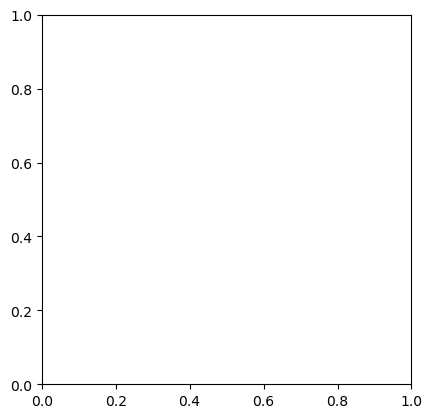

In [ ]:
plt.imshow(train_gen)

## 1.  Model 1.0 using Transfer Learning.

In [ ]:
vgg16_model = VGG16(
    include_top=False,
    weights='imagenet',
    input_shape=(64, 64, 3)
)

In [ ]:
vgg16_model.summary()

Model: "vgg16"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_4 (InputLayer)        [(None, 64, 64, 3)]       0         
                                                                 
 block1_conv1 (Conv2D)       (None, 64, 64, 64)        1792      
                                                                 
 block1_conv2 (Conv2D)       (None, 64, 64, 64)        36928     
                                                                 
 block1_pool (MaxPooling2D)  (None, 32, 32, 64)        0         
                                                                 
 block2_conv1 (Conv2D)       (None, 32, 32, 128)       73856     
                                                                 
 block2_conv2 (Conv2D)       (None, 32, 32, 128)       147584    
                                                                 
 block2_pool (MaxPooling2D)  (None, 16, 16, 128)       0     

In [ ]:
for layer in vgg16_model.layers[:5]:
    layer.trainable = False

In [ ]:
x = vgg16_model.output
x = BatchNormalization()(x)
x = Dropout(0.5)(x)
x = Dense(1024, activation="relu")(x)
x = Flatten()(x)
prediction = Dense(2, activation="softmax")(x)

model = Model(inputs= vgg16_model.input, outputs= prediction)

early_stop = EarlyStopping(monitor='val_loss', mode='auto', verbose=1, patience=3, restore_best_weights=True)

model.compile(loss="binary_crossentropy", optimizer=SGD(learning_rate=0.003, momentum=0.9), metrics=["acc"])

model.summary()

Model: "model_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_4 (InputLayer)        [(None, 64, 64, 3)]       0         
                                                                 
 block1_conv1 (Conv2D)       (None, 64, 64, 64)        1792      
                                                                 
 block1_conv2 (Conv2D)       (None, 64, 64, 64)        36928     
                                                                 
 block1_pool (MaxPooling2D)  (None, 32, 32, 64)        0         
                                                                 
 block2_conv1 (Conv2D)       (None, 32, 32, 128)       73856     
                                                                 
 block2_conv2 (Conv2D)       (None, 32, 32, 128)       147584    
                                                                 
 block2_pool (MaxPooling2D)  (None, 16, 16, 128)       0   

In [ ]:
history = model.fit(
    train_gen,
    epochs=50,
    validation_data=valid_gen,
    steps_per_epoch  = 5)

Epoch 1/50
5/5 [==============================] - 56s 13s/step - loss: 0.7428 - acc: 0.5562 - val_loss: 3.1723 - val_acc: 0.5162
Epoch 2/50
5/5 [==============================] - 49s 12s/step - loss: 0.7210 - acc: 0.4688 - val_loss: 1.7509 - val_acc: 0.4838
Epoch 3/50
5/5 [==============================] - 48s 11s/step - loss: 0.7076 - acc: 0.4500 - val_loss: 2.1159 - val_acc: 0.5162
Epoch 4/50
5/5 [==============================] - 47s 11s/step - loss: 0.7151 - acc: 0.4750 - val_loss: 14.8600 - val_acc: 0.4838
Epoch 5/50
5/5 [==============================] - 48s 11s/step - loss: 0.7115 - acc: 0.4812 - val_loss: 0.7168 - val_acc: 0.4911
Epoch 6/50
5/5 [==============================] - 47s 11s/step - loss: 0.6972 - acc: 0.5188 - val_loss: 0.9093 - val_acc: 0.4838
Epoch 7/50
5/5 [==============================] - 51s 12s/step - loss: 0.6990 - acc: 0.5562 - val_loss: 0.7142 - val_acc: 0.4827
Epoch 8/50
5/5 [==============================] - 51s 12s/step - loss: 0.7112 - acc: 0.4812 - va

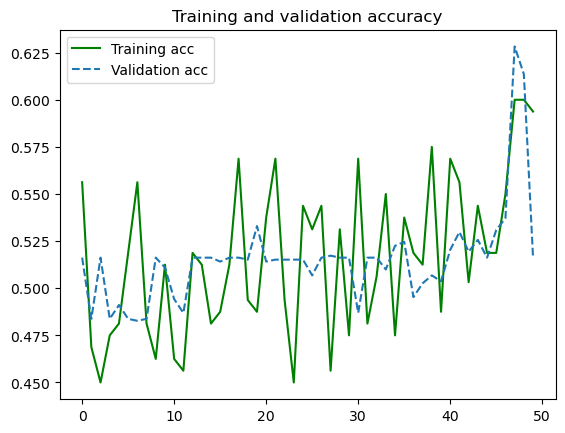

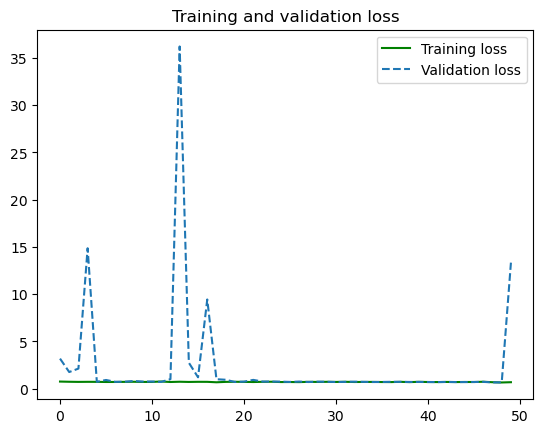

In [ ]:
acc = history.history['acc']
val_acc = history.history['val_acc']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(len(acc))

plt.plot(epochs, acc, 'g-', label='Training acc')
plt.plot(epochs, val_acc, '--', label='Validation acc')
plt.title('Training and validation accuracy')
plt.legend()

plt.figure()

plt.plot(epochs, loss, 'g-', label='Training loss')
plt.plot(epochs, val_loss, '--', label='Validation loss')
plt.title('Training and validation loss')
plt.legend()

plt.show()


1/1 [==============================] - 0s 31ms/step
This image most likely belongs to 0 with a 67.36 percent confidence.


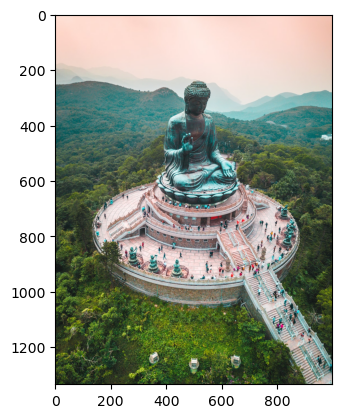

In [ ]:
image = "data/test/photo-1513415564515-763d91423bdd.jpeg"
img = tf.keras.utils.load_img(image, target_size=[64, 64])
input_arr = tf.keras.utils.img_to_array(img)
input_arr = np.array([input_arr])  # Convert single image to a batch.
predictions = model.predict(input_arr)

score = tf.nn.softmax(predictions[0])

print(
    "This image most likely belongs to {} with a {:.2f} percent confidence."
    .format(class_names[np.argmax(score)], 100 * np.max(score))
)

import matplotlib.image as mpimg
img = mpimg.imread(image)
plt.imshow(img)
plt.show()

# **Implementation of Deep Learning PyTorch YOLO v5 model.**

In [ ]:
# Import PyTorch framework with other libraries.
import torch
import os
from IPython.display import Image, clear_output  # to display images

print(f"Setup complete. Using torch {torch.__version__} ({torch.cuda.get_device_properties(0).name if torch.cuda.is_available() else 'CPU'})")

Setup complete. Using torch 1.13.0+cu116 (CPU)


In [ ]:
# this is the YAML file Roboflow wrote for us that we're loading into this notebook with our data
%cat {dataset.location}/data.yaml

names:
- '16'
- monument
nc: 2
roboflow:
  license: MIT
  project: ateet
  url: https://universe.roboflow.com/thestarclass/ateet/dataset/1
  version: 1
  workspace: thestarclass
test: ../test/images
train: Ateet-1/train/images
val: Ateet-1/valid/images


In [ ]:
# define number of classes based on YAML
import yaml
with open(dataset.location + "/data.yaml", 'r') as stream:
    num_classes = str(yaml.safe_load(stream)['nc'])

In [ ]:
#this is the model configuration, which is in yolov5x.yaml file.
%cat /content/drive/MyDrive/Project/yolov5/models/yolov5x.yaml

# YOLOv5 🚀 by Ultralytics, GPL-3.0 license

# Parameters
nc: 80  # number of classes
depth_multiple: 1.33  # model depth multiple
width_multiple: 1.25  # layer channel multiple
anchors:
  - [10,13, 16,30, 33,23]  # P3/8
  - [30,61, 62,45, 59,119]  # P4/16
  - [116,90, 156,198, 373,326]  # P5/32

# YOLOv5 v6.0 backbone
backbone:
  # [from, number, module, args]
  [[-1, 1, Conv, [64, 6, 2, 2]],  # 0-P1/2
   [-1, 1, Conv, [128, 3, 2]],  # 1-P2/4
   [-1, 3, C3, [128]],
   [-1, 1, Conv, [256, 3, 2]],  # 3-P3/8
   [-1, 6, C3, [256]],
   [-1, 1, Conv, [512, 3, 2]],  # 5-P4/16
   [-1, 9, C3, [512]],
   [-1, 1, Conv, [1024, 3, 2]],  # 7-P5/32
   [-1, 3, C3, [1024]],
   [-1, 1, SPPF, [1024, 5]],  # 9
  ]

# YOLOv5 v6.0 head
head:
  [[-1, 1, Conv, [512, 1, 1]],
   [-1, 1, nn.Upsample, [None, 2, 'nearest']],
   [[-1, 6], 1, Concat, [1]],  # cat backbone P4
   [-1, 3, C3, [512, False]],  # 13

   [-1, 1, Conv, [256, 1, 1]],
   [-1, 1, nn.Upsample, [None, 2, 'nearest']],
   [[-1, 4], 1, Concat, [1]]

In [ ]:
#customize iPython writefile so we can write variables
from IPython.core.magic import register_line_cell_magic

@register_line_cell_magic
def writetemplate(line, cell):
    with open(line, 'w') as f:
        f.write(cell.format(**globals()))

In [ ]:
%%writetemplate /content/drive/MyDrive/Project/yolov5/models/yolov5x.yaml

# parameters
nc: {num_classes}  # number of classes
depth_multiple: 0.33  # model depth multiple
width_multiple: 0.50  # layer channel multiple

# anchors
anchors:
  - [10,13, 16,30, 33,23]  # P3/8
  - [30,61, 62,45, 59,119]  # P4/16
  - [116,90, 156,198, 373,326]  # P5/32

# YOLOv5 backbone
backbone:
  # [from, number, module, args]
  [[-1, 1, Focus, [64, 3]],  # 0-P1/2
   [-1, 1, Conv, [128, 3, 2]],  # 1-P2/4
   [-1, 3, BottleneckCSP, [128]],
   [-1, 1, Conv, [256, 3, 2]],  # 3-P3/8
   [-1, 9, BottleneckCSP, [256]],
   [-1, 1, Focus, [64, 3]],  # 0-P1/2
   [-1, 1, Conv, [128, 3, 2]],  # 1-P2/4
   [-1, 1, Conv, [512, 3, 2]],  # 5-P4/16
   [-1, 9, BottleneckCSP, [512]],
   [-1, 1, Conv, [1024, 3, 2]],  # 7-P5/32
   [-1, 1, SPP, [1024, [5, 9, 13]]],
   [-1, 3, BottleneckCSP, [1024, False]],  # 9
  ]

# YOLOv5 head
head:
  [[-1, 1, Conv, [512, 1, 1]],
   [-1, 1, nn.Upsample, [None, 2, 'nearest']],
   [[-1, 6], 1, Concat, [1]],  # cat backbone P4
   [-1, 3, BottleneckCSP, [512, False]],  # 13

   [-1, 1, Conv, [256, 1, 1]],
   [-1, 1, nn.Upsample, [None, 2, 'nearest']],
   [[-1, 6], 1, Concat, [1]],  # cat backbone P4
   [-1, 3, BottleneckCSP, [512, False]],
   [[-1, 4], 1, Concat, [1]],  # cat   backbone P3
   [-1, 3, BottleneckCSP, [256, False]],  # 17 (P3/8-small)

   [-1, 1, Conv, [256, 3, 2]],
   [[-1, 14], 1, Concat, [1]],  # cat head P4
   [-1, 3, BottleneckCSP, [512, False]],  # 20 (P4/16-medium)

   [-1, 1, Conv, [512, 3, 2]],
   [[-1, 10], 1, Concat, [1]],  # cat head P5
   [-1, 3, BottleneckCSP, [1024, False]],  # 23 (P5/32-large)

   [[17, 20, 23], 1, Detect, [nc, anchors]],  # Detect(P3, P4, P5)
  ]

### Train Custom Yolov5 model with Monuments Aerial Imagery.

In [ ]:
!python train.py --img 416 --batch 10 --epochs 150 --data {dataset.location}/data.yaml --weights yolov5x.pt --name yolov5s_results  --cache

train: weights=yolov5x.pt, cfg=, data=/content/drive/MyDrive/Project/yolov5/Ateet-1/data.yaml, hyp=data/hyps/hyp.scratch-low.yaml, epochs=150, batch_size=10, imgsz=416, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, noplots=False, evolve=None, bucket=, cache=ram, image_weights=False, device=, multi_scale=False, single_cls=False, optimizer=SGD, sync_bn=False, workers=8, project=runs/train, name=yolov5s_results, exist_ok=False, quad=False, cos_lr=False, label_smoothing=0.0, patience=100, freeze=[0], save_period=-1, seed=0, local_rank=-1, entity=None, upload_dataset=False, bbox_interval=-1, artifact_alias=latest
github: up to date with https://github.com/ultralytics/yolov5 ✅
YOLOv5 🚀 v7.0-32-g357cde9 Python-3.8.16 torch-1.13.0+cu116 CUDA:0 (Tesla T4, 15110MiB)

hyperparameters: lr0=0.01, lrf=0.01, momentum=0.937, weight_decay=0.0005, warmup_epochs=3.0, warmup_momentum=0.8, warmup_bias_lr=0.1, box=0.05, cls=0.5, cls_pw=1.0, obj=1.0, obj_pw=1.0, iou_t=0.2, anchor_t

### TensorBoard Visualization of Mean Average Precision (mAP), Precision (P) and Recall (R).

In [ ]:
# Start tensorboard
# Launch after you have started training
# logs save in the folder "runs"
%load_ext tensorboard
%tensorboard --logdir runs

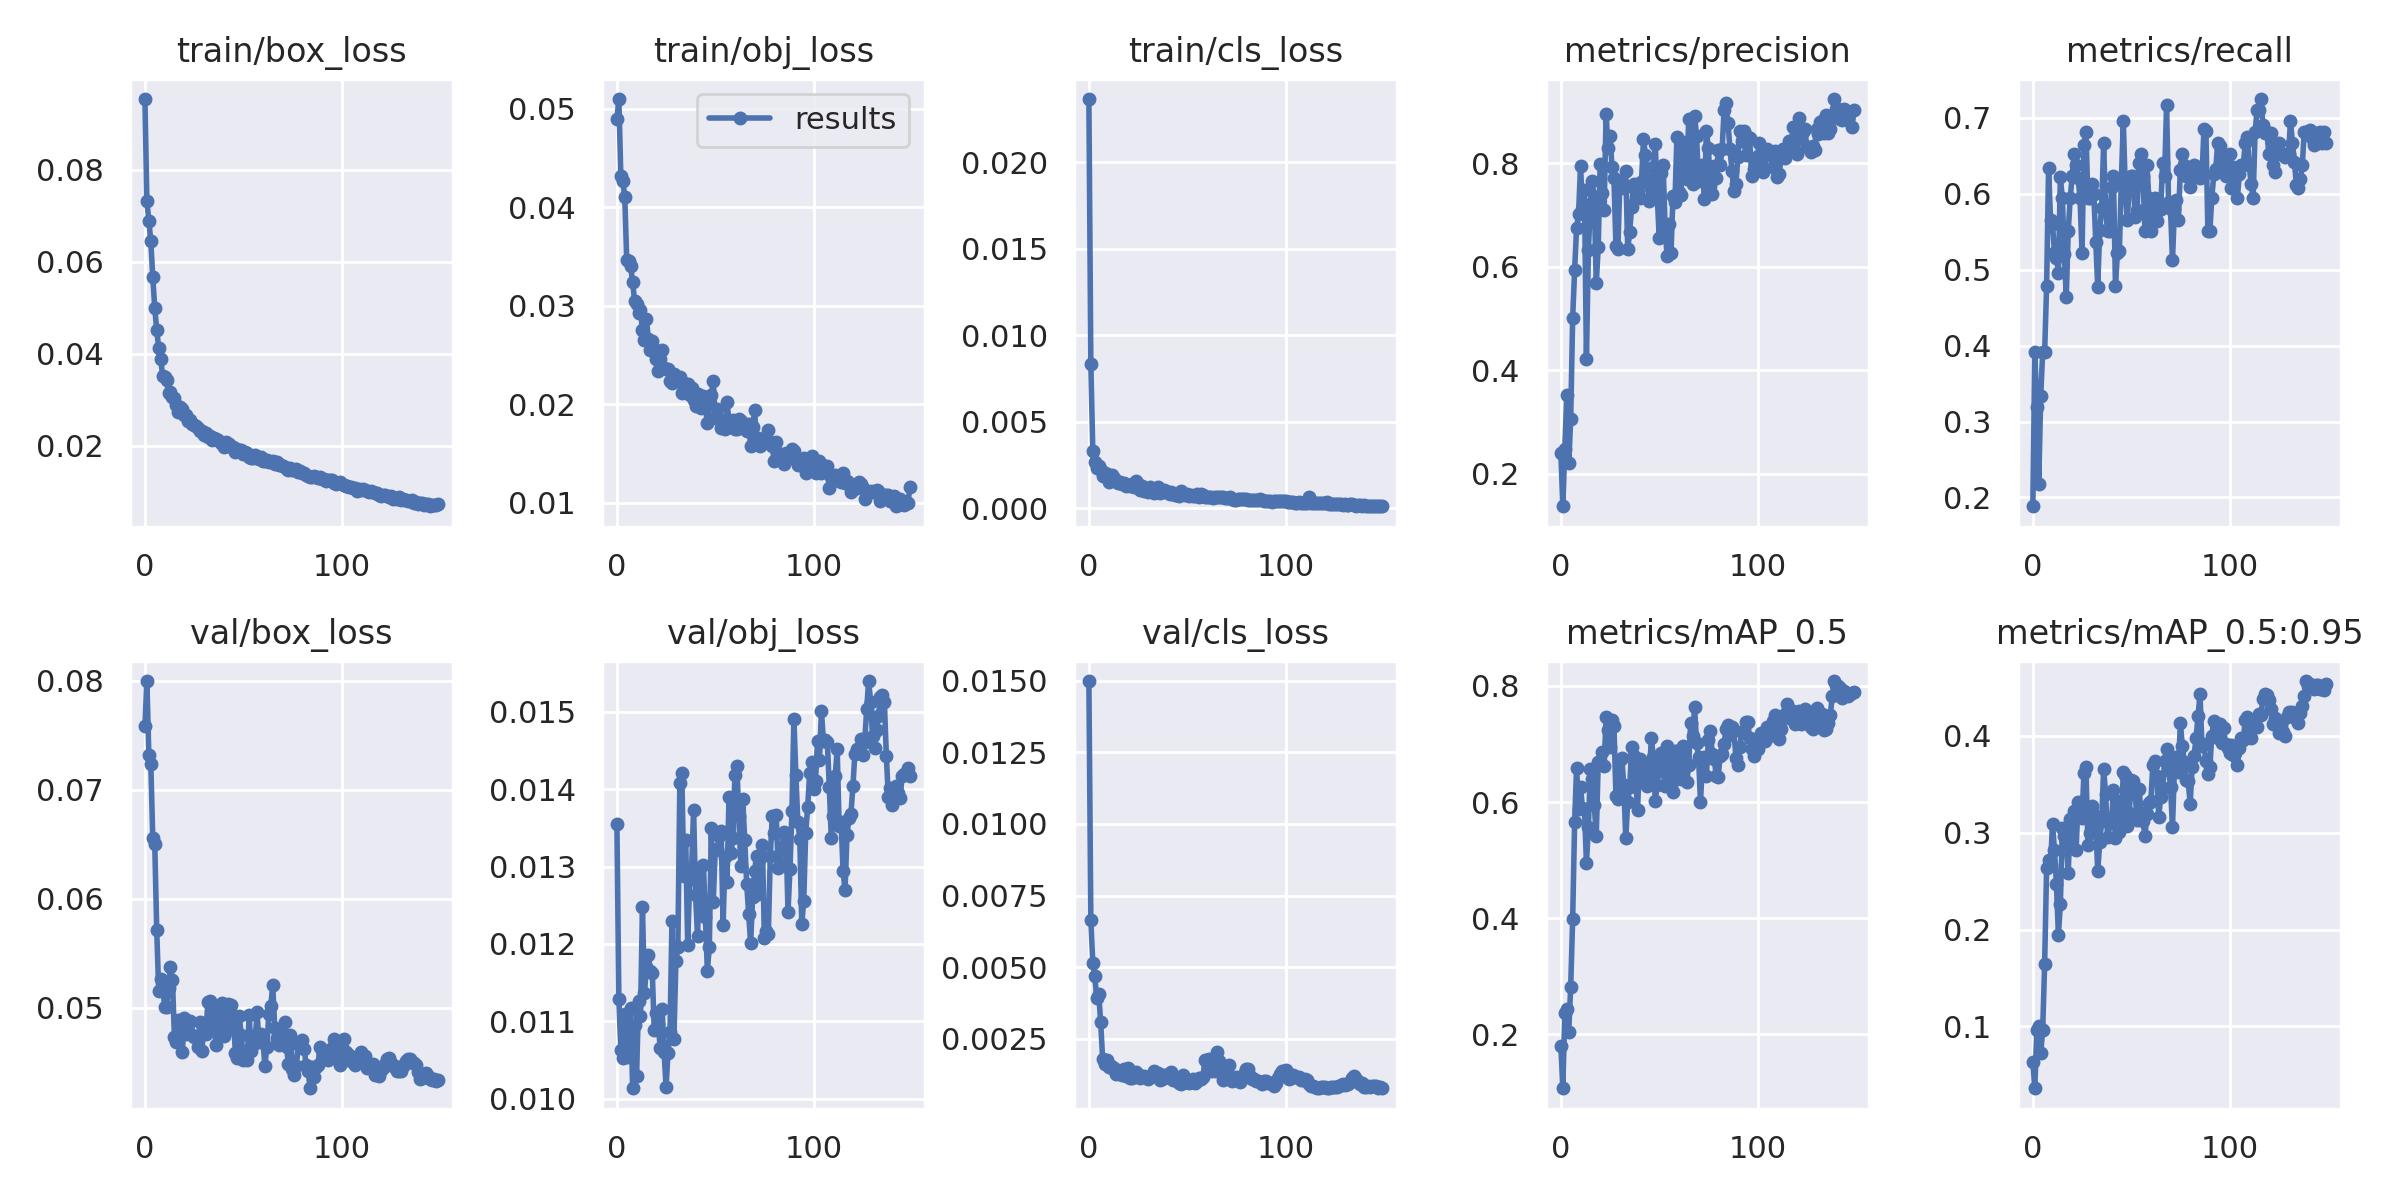

In [ ]:
# we can also output some older school graphs if the tensor board isn't working for whatever reason... 
from utils.plots import plot_results  # plot results.txt as results.png
Image(filename='/content/drive/MyDrive/Project/yolov5/runs/train/yolov5s_results/results.png', width=1000)  # view results.png

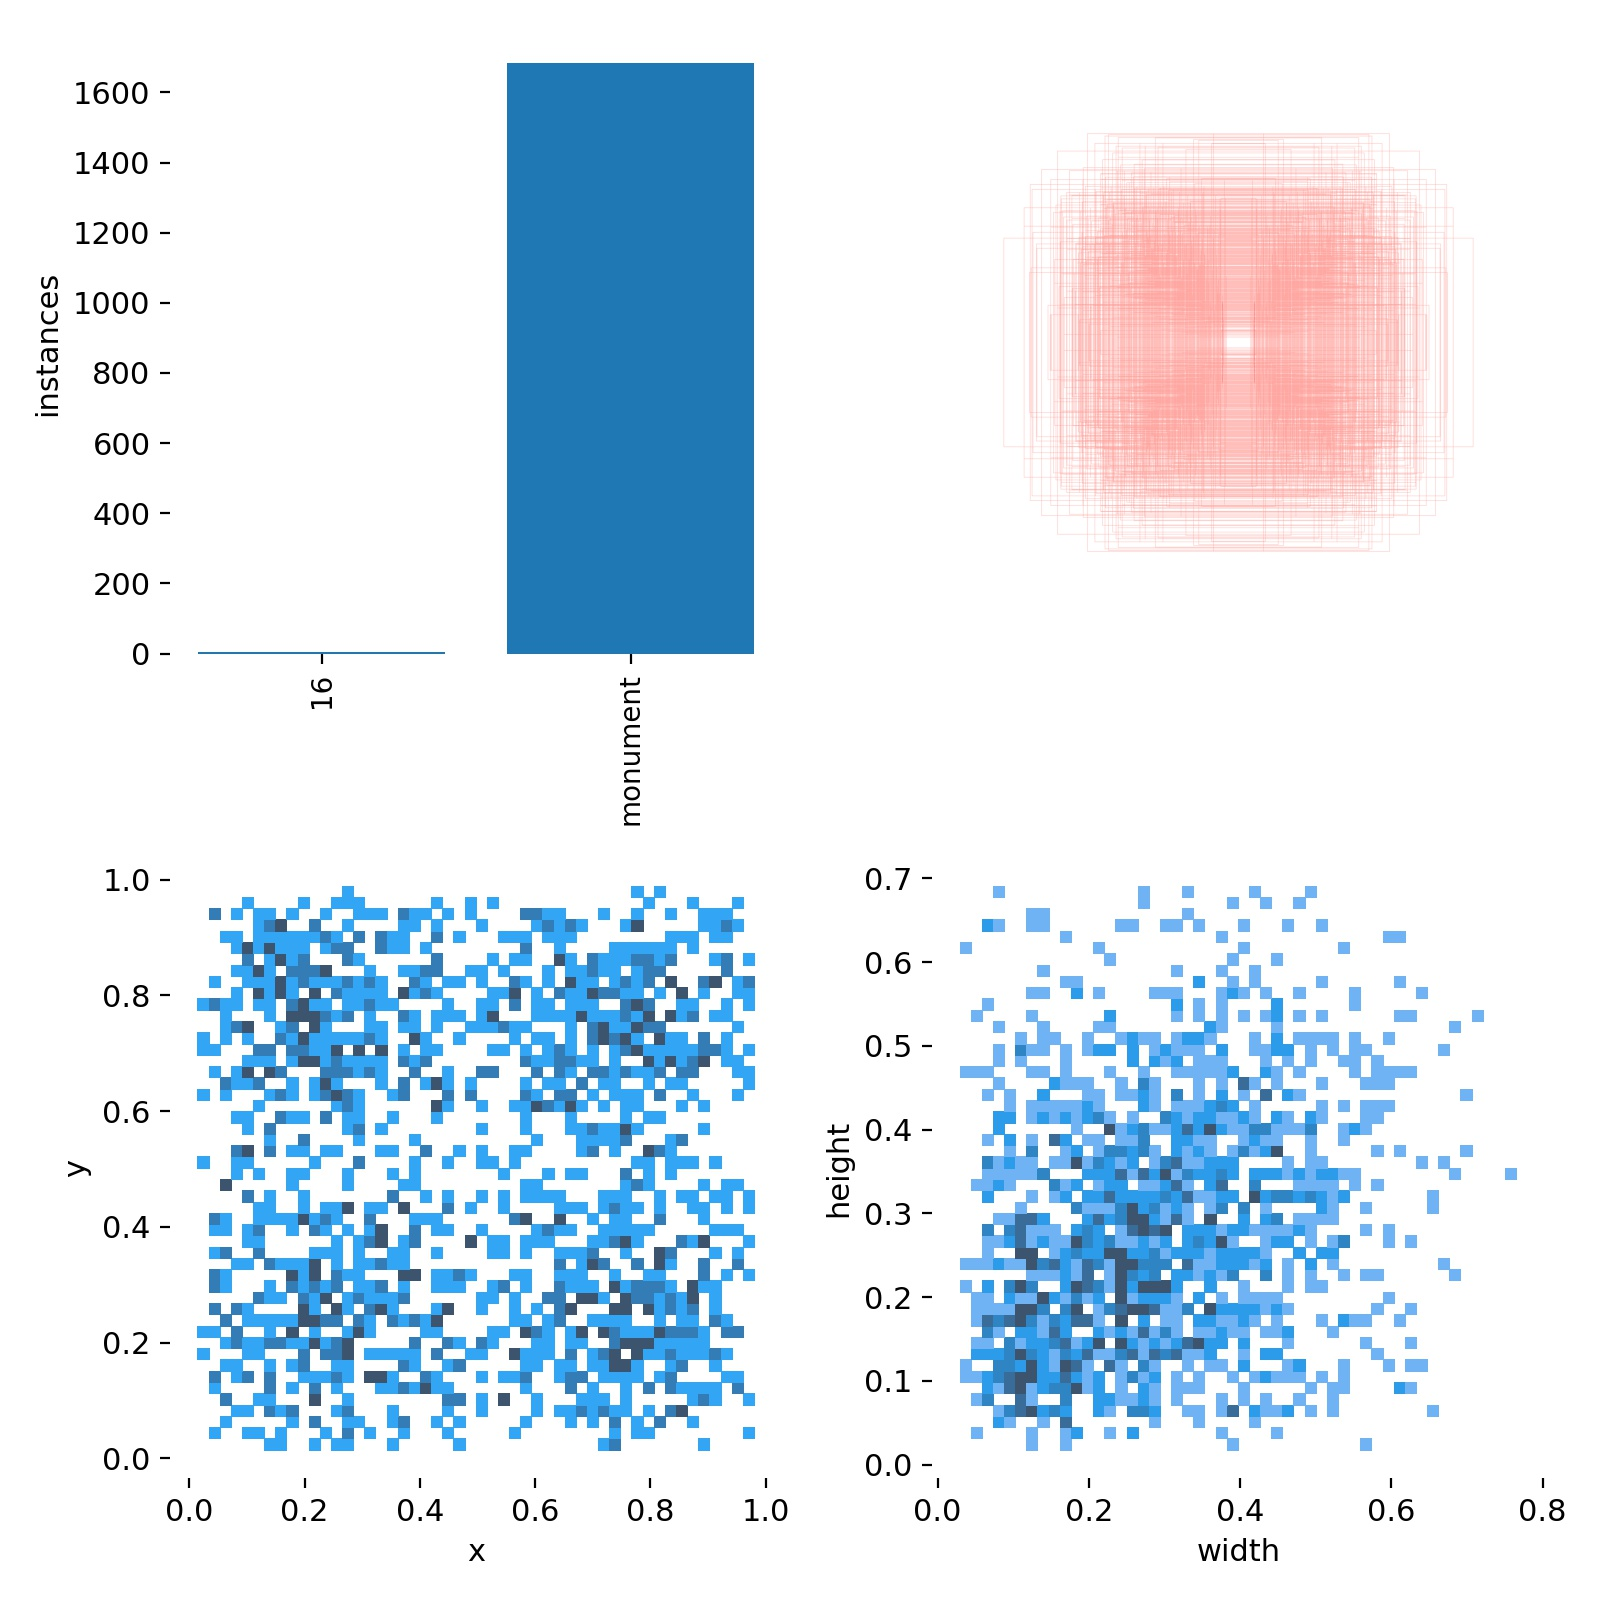

In [ ]:
# View Lables matrix and Anchor boxes of Labels in image.
Image(filename='/content/drive/MyDrive/Project/yolov5/runs/train/yolov5s_results/labels.jpg', width=1000)  # view lables.jpg

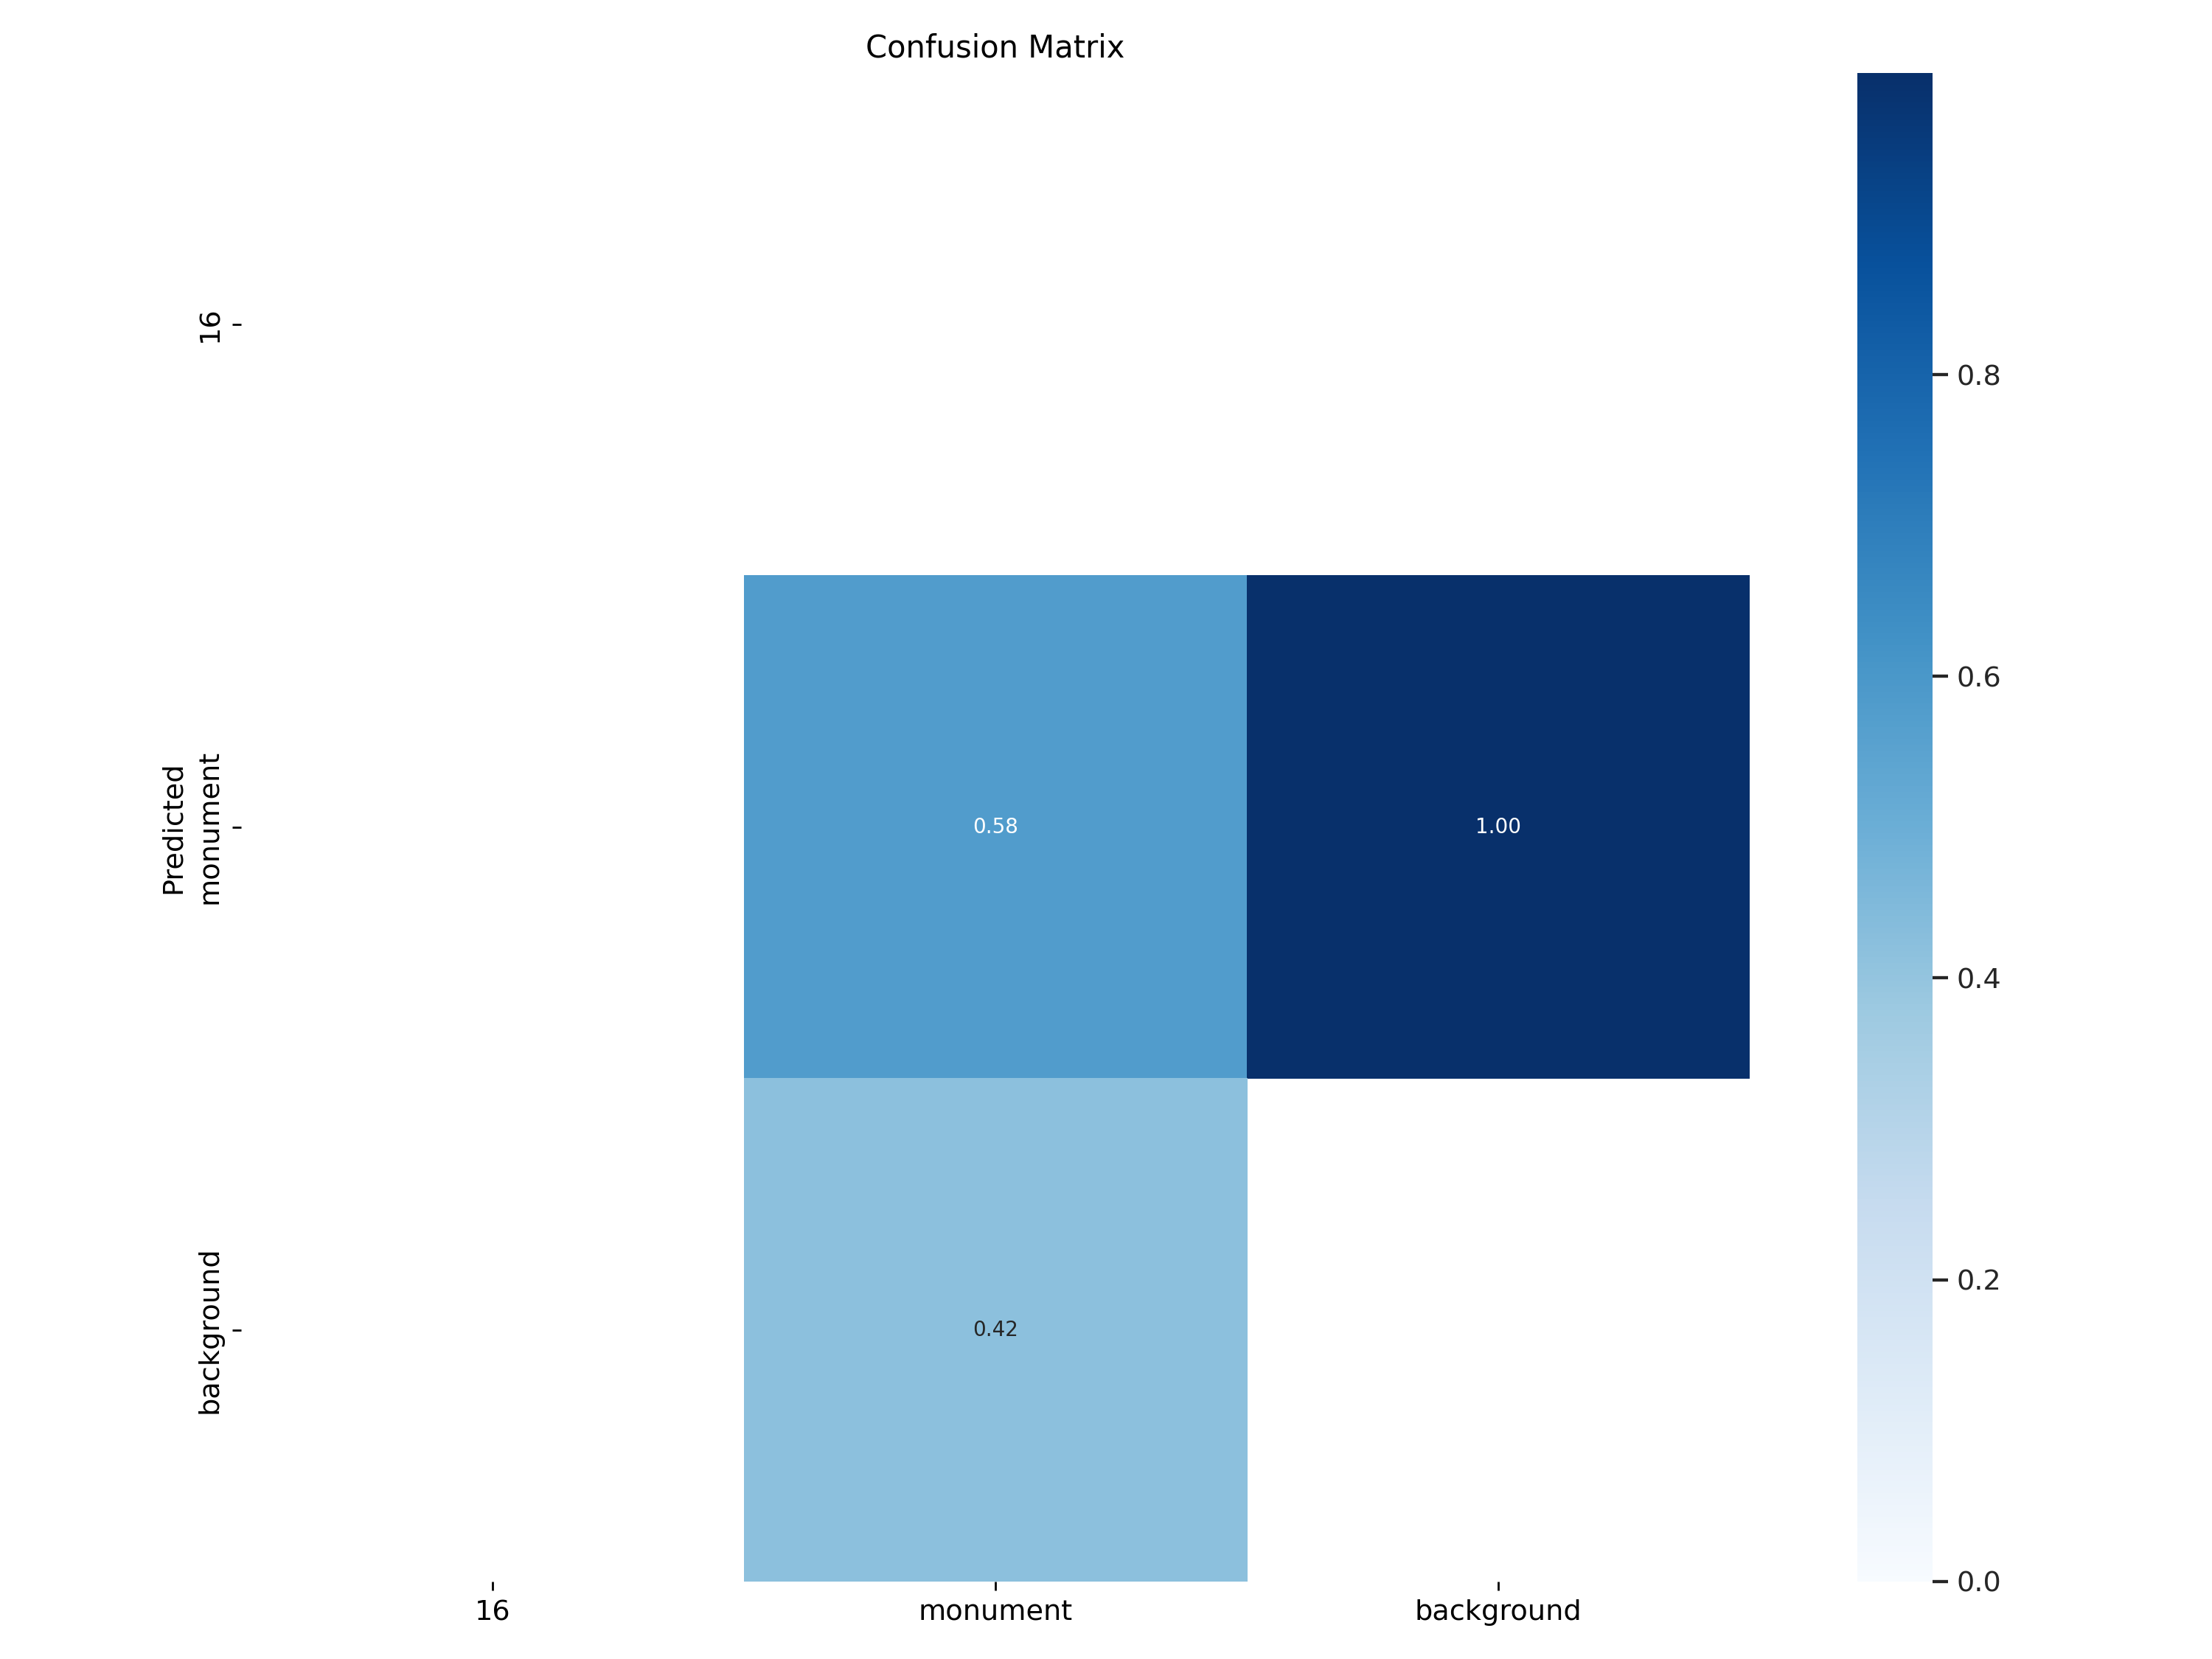

In [ ]:
# Confusion Matrix with respect to Actual Labels and Predicted Labels of Monuments and Background.
Image(filename='/content/drive/MyDrive/Project/yolov5/runs/train/yolov5s_results/confusion_matrix.png', width=1000)  # view confusion_matrix.png

### Visualization of Ground Truth data with bounding boxes.

GROUND TRUTH TRAINING DATA:


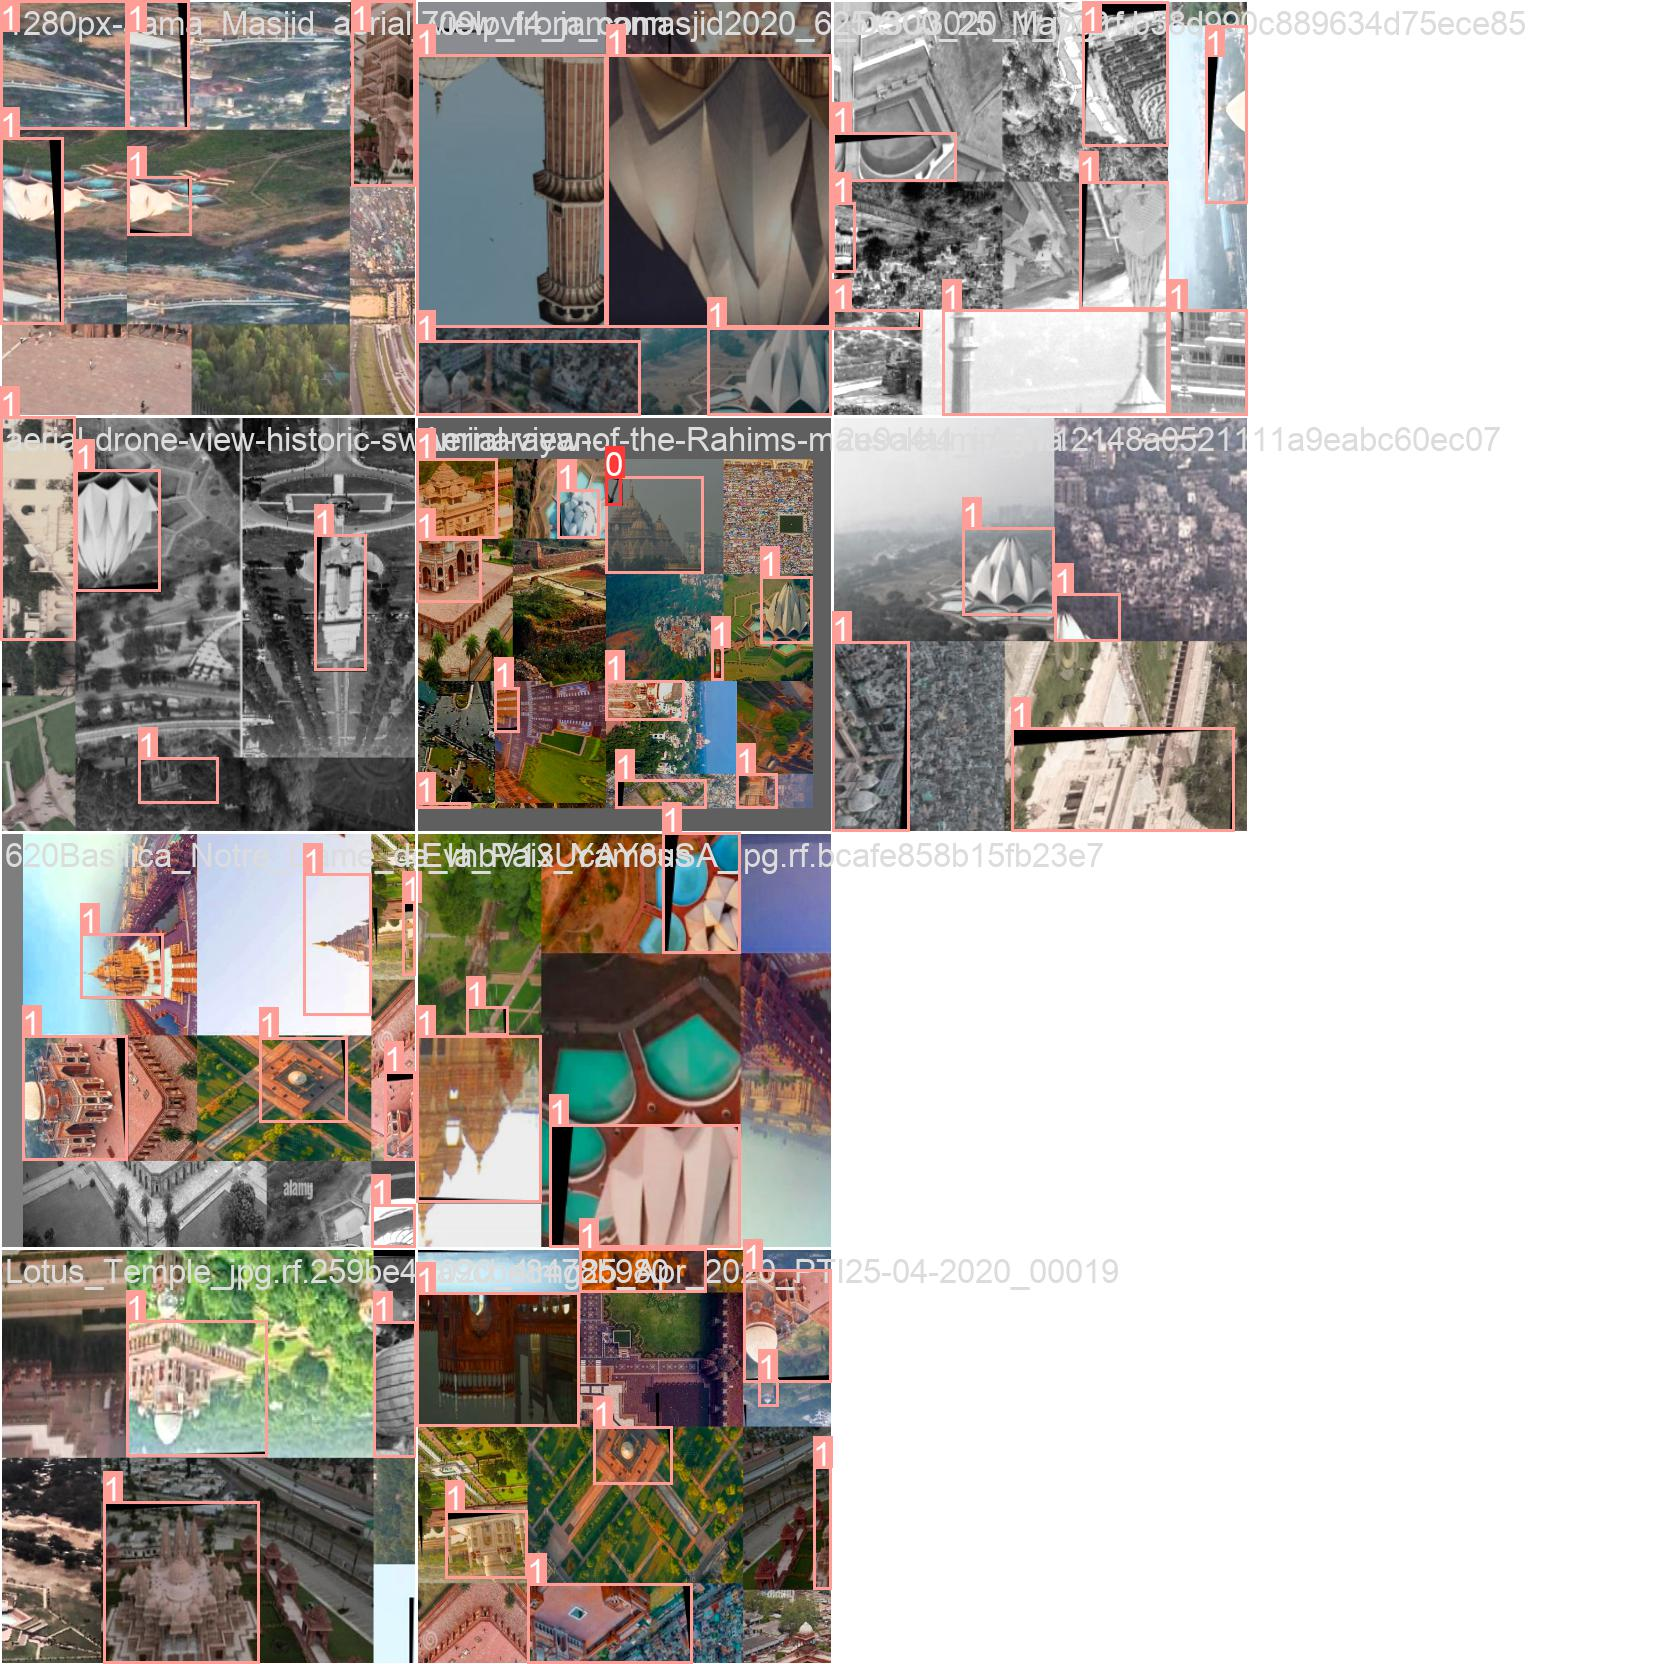

In [ ]:
# First display our ground truth data
print("GROUND TRUTH TRAINING DATA:")
Image(filename='/content/drive/MyDrive/Project/yolov5/runs/train/yolov5s_results/train_batch0.jpg', width=900)

### Visualization of Data Augmented  Dataset.

GROUND TRUTH AUGMENTED TRAINING DATA:


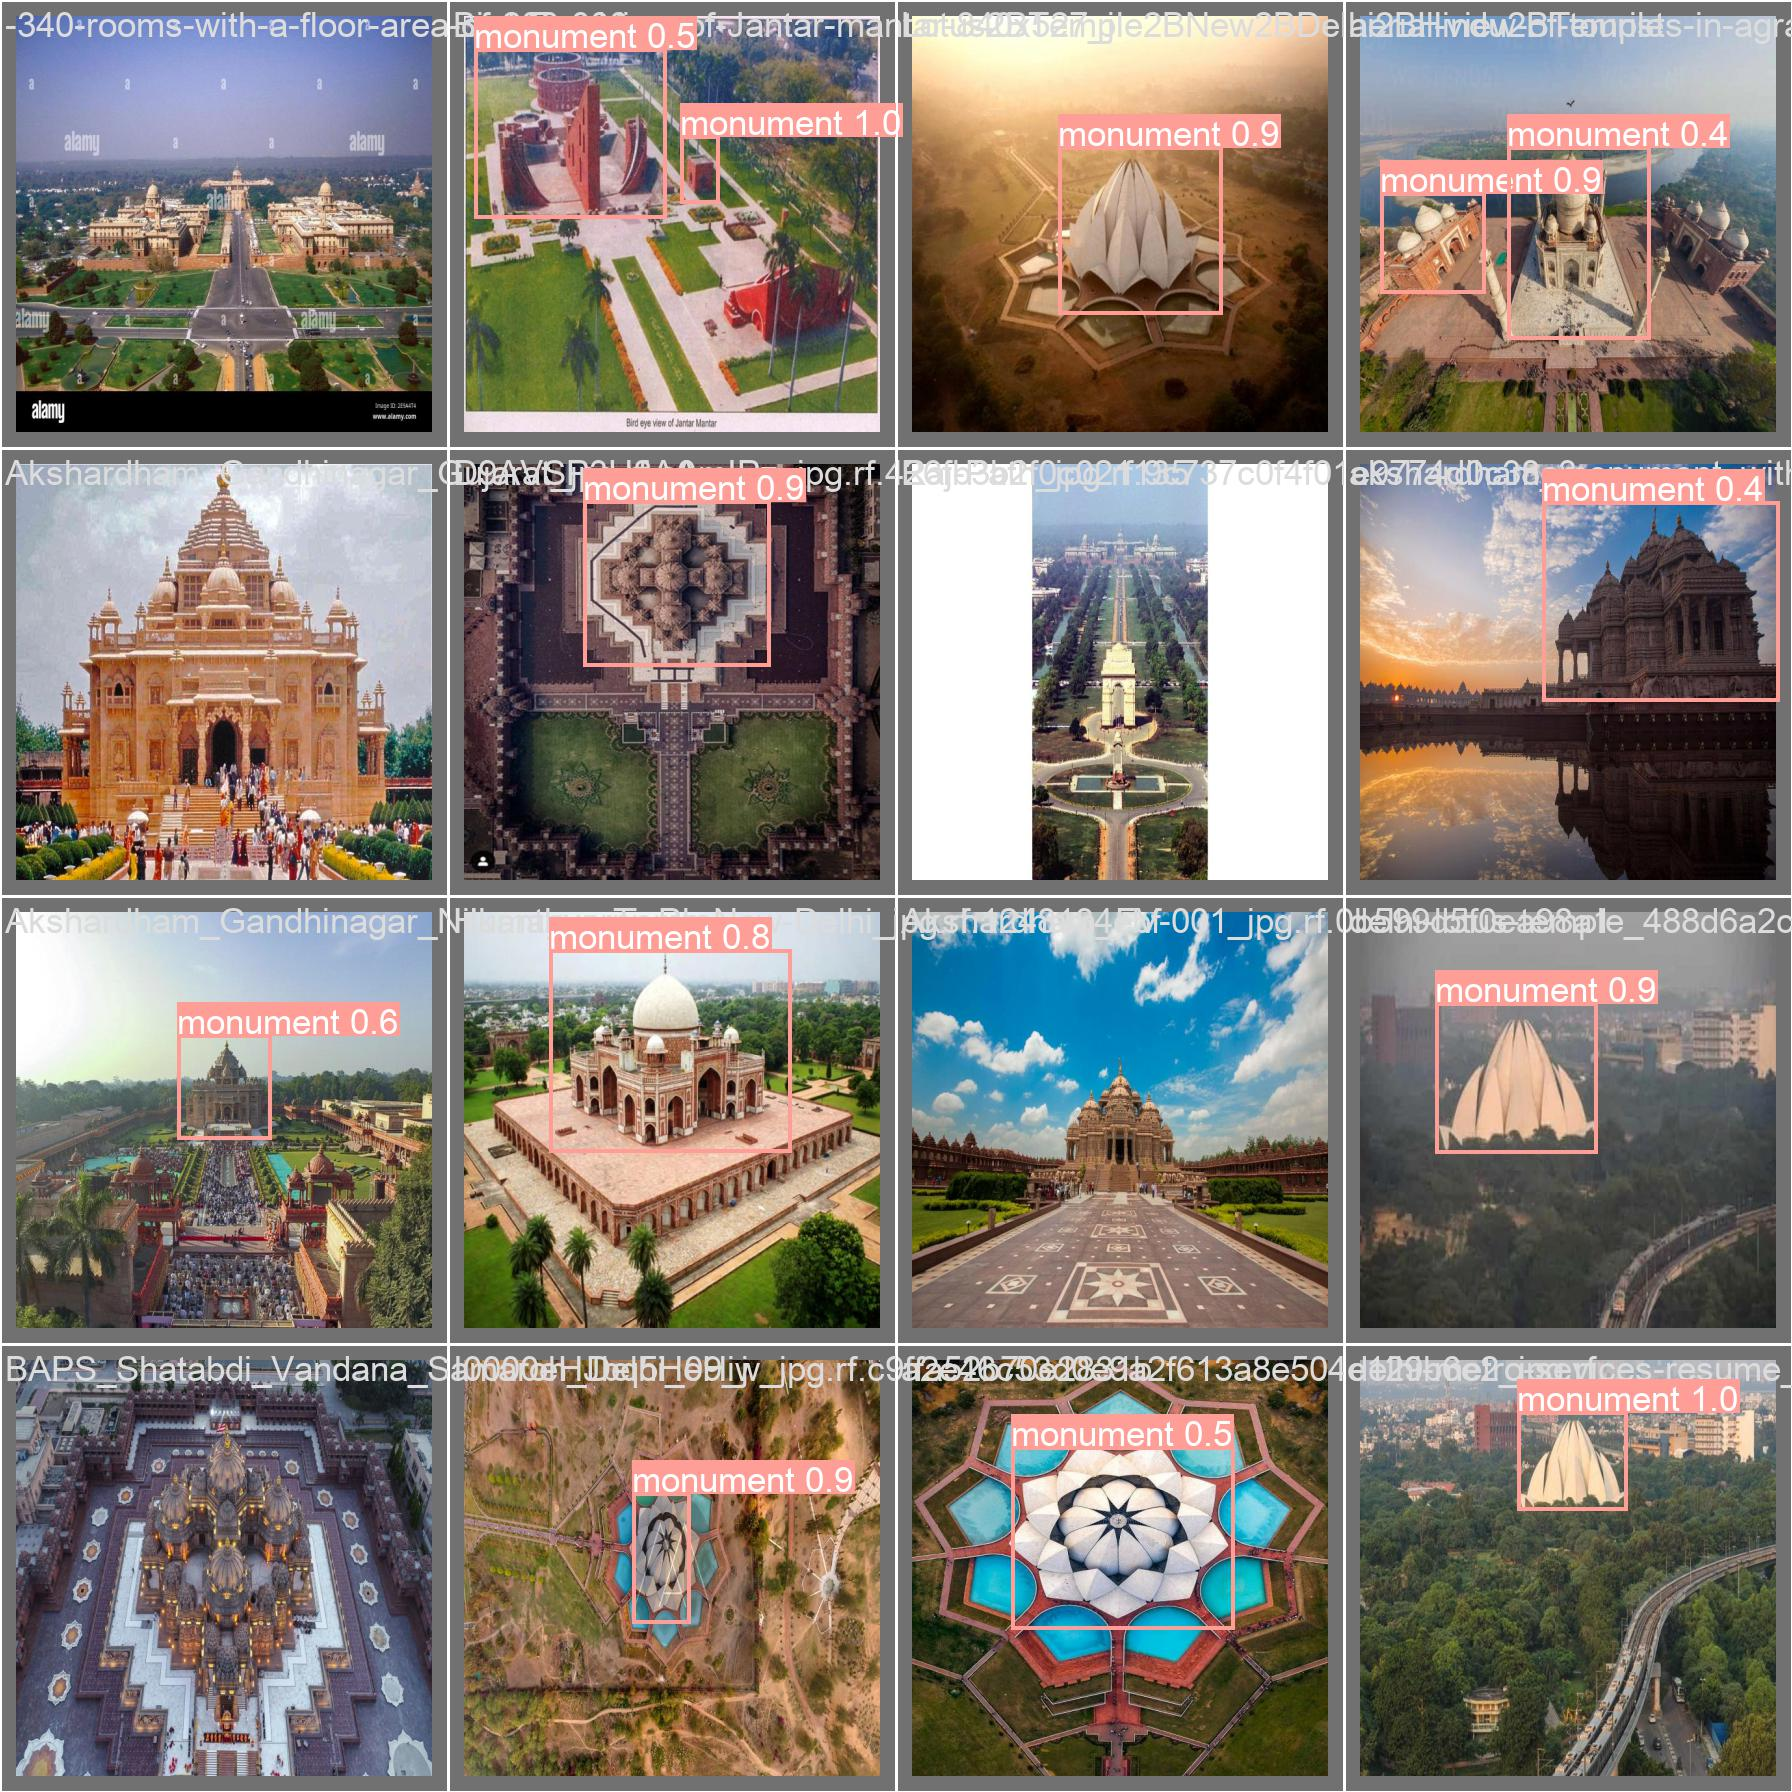

In [ ]:
# print out an augmented training example
print("GROUND TRUTH AUGMENTED TRAINING DATA:")
Image(filename='/content/drive/MyDrive/Project/yolov5/runs/train/yolov5s_results/val_batch0_pred.jpg', width=900)

In [ ]:
# trained weights are saved by default in our weights folder
%ls /content/drive/MyDrive/Project/yolov5/runs

detect/  train/  val/


In [ ]:
%ls /content/drive/MyDrive/Project/yolov5/runs/train/yolov5s_results/weights

best.pb  best_saved_model/  best_web_model.zip
best.pt  best_web_model/    last.pt


In [ ]:
%cd /content/drive/MyDrive/Project/yolov5

/content/drive/MyDrive/Project/yolov5


### Testing the model prediction and detection of monuments on Test Dataset.

In [ ]:
# when we ran this, we saw .007 second inference time. That is 140 FPS on a TESLA P100!  
# use the best weig
!python detect.py --weights runs/train/yolov5s_results/weights/best.pt --img 416 --conf 0.8 --source {dataset.location}/test/images

detect: weights=['runs/train/yolov5s_results/weights/best.pt'], source=/content/drive/MyDrive/Project/yolov5/Ateet-1/test/images, data=data/coco128.yaml, imgsz=[416, 416], conf_thres=0.8, iou_thres=0.45, max_det=1000, device=, view_img=False, save_txt=False, save_conf=False, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, visualize=False, update=False, project=runs/detect, name=exp, exist_ok=False, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 v7.0-32-g357cde9 Python-3.8.16 torch-1.13.0+cu116 CUDA:0 (Tesla T4, 15110MiB)

Fusing layers... 
Model summary: 322 layers, 86180143 parameters, 0 gradients, 203.8 GFLOPs
image 1/10 /content/drive/MyDrive/Project/yolov5/Ateet-1/test/images/02_jpg.rf.7a1093e2d1bbc2ce555ab25aa2a3fb29.jpg: 416x416 (no detections), 47.3ms
image 2/10 /content/drive/MyDrive/Project/yolov5/Ateet-1/test/images/1200px-Jantar_Delhi_jpg.rf.b339116706d538b253b6df93248709ed.jpg: 416x416 3 mon

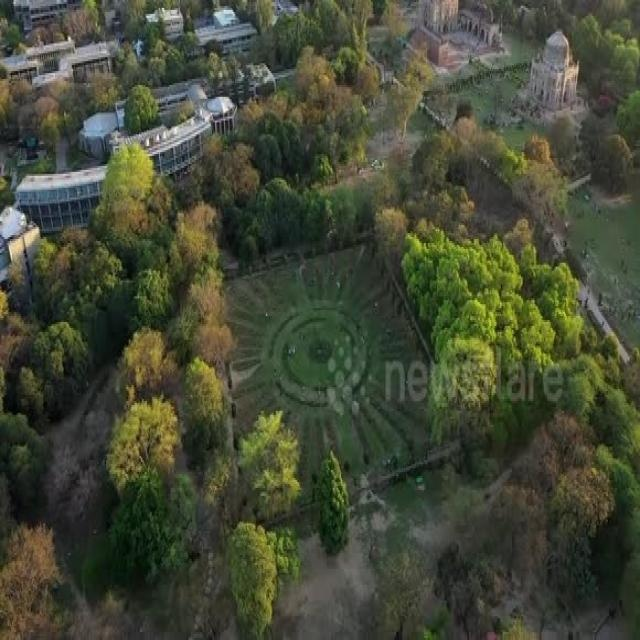

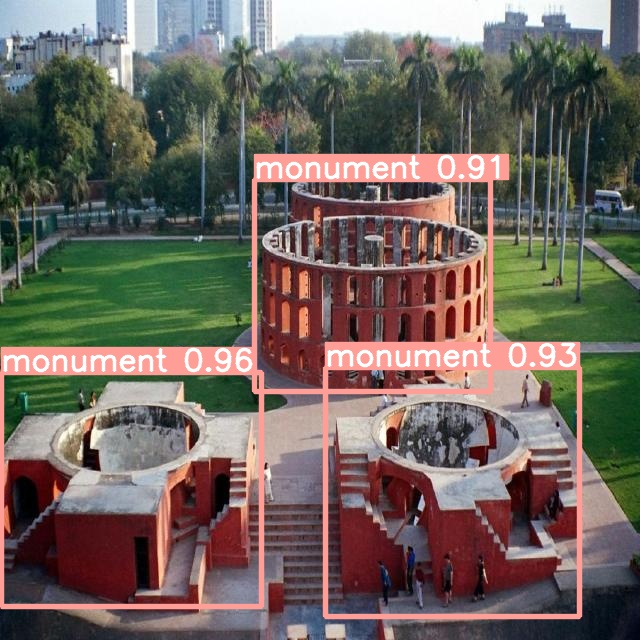

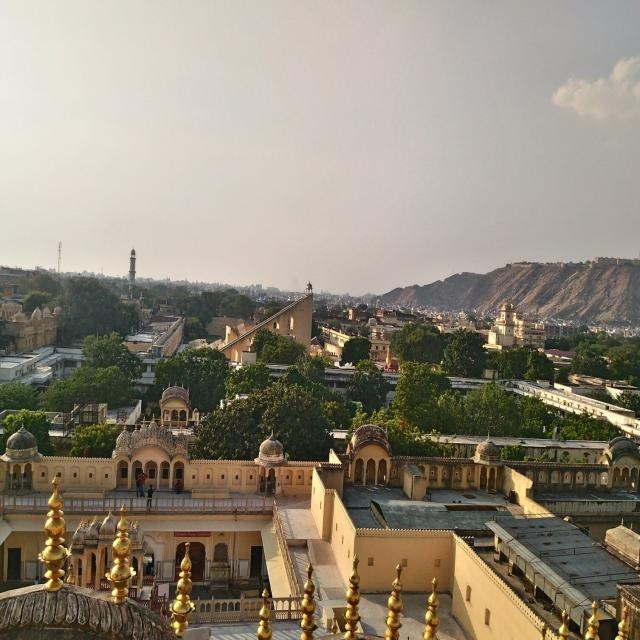

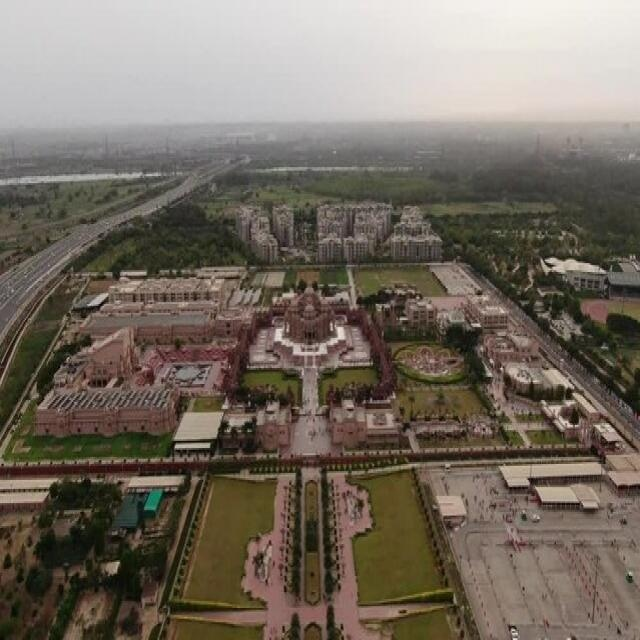

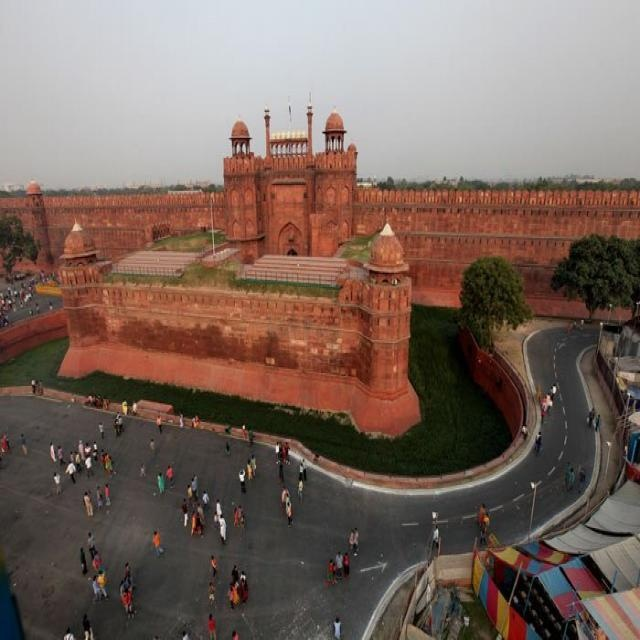

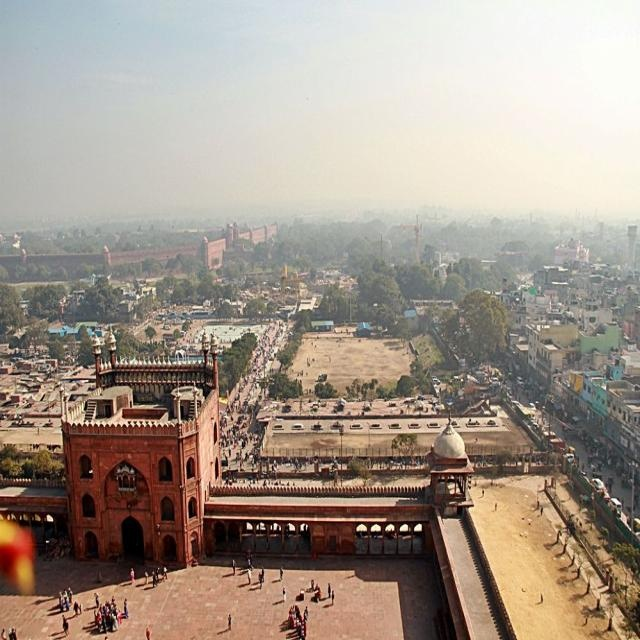

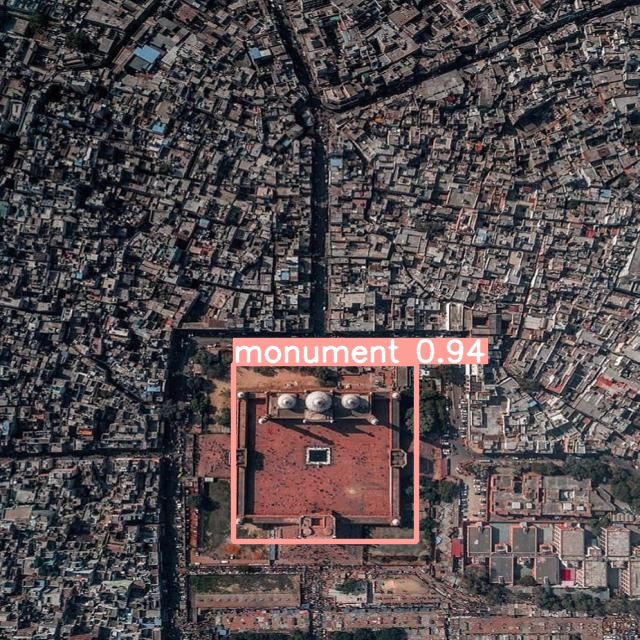

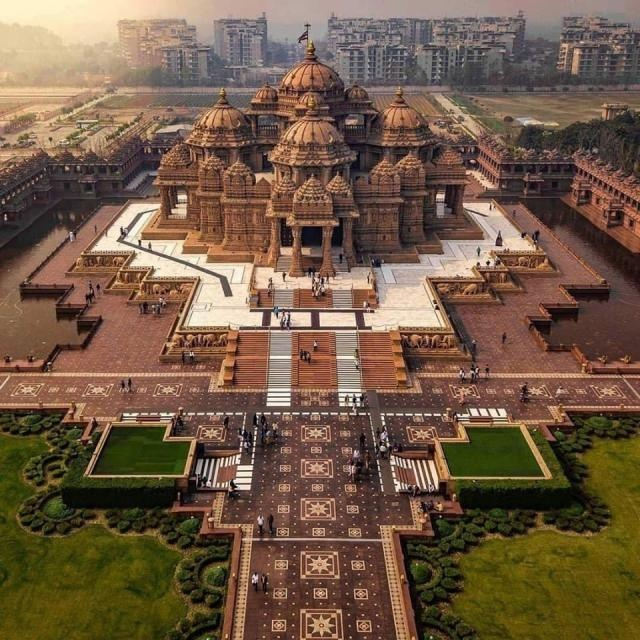

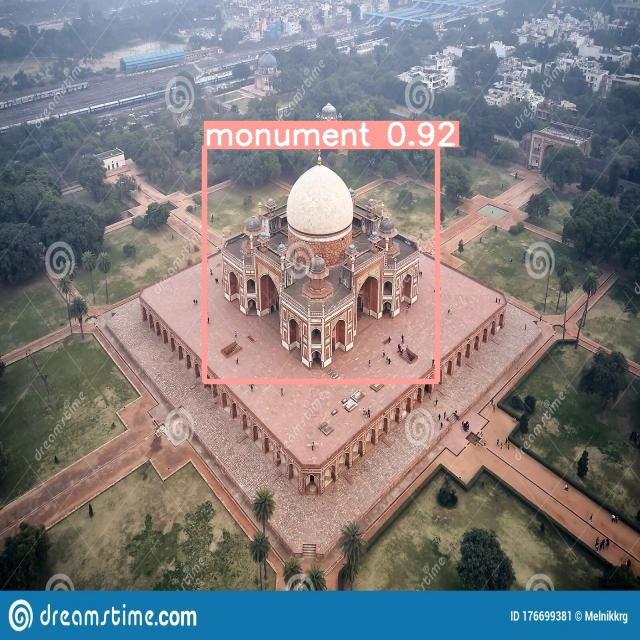

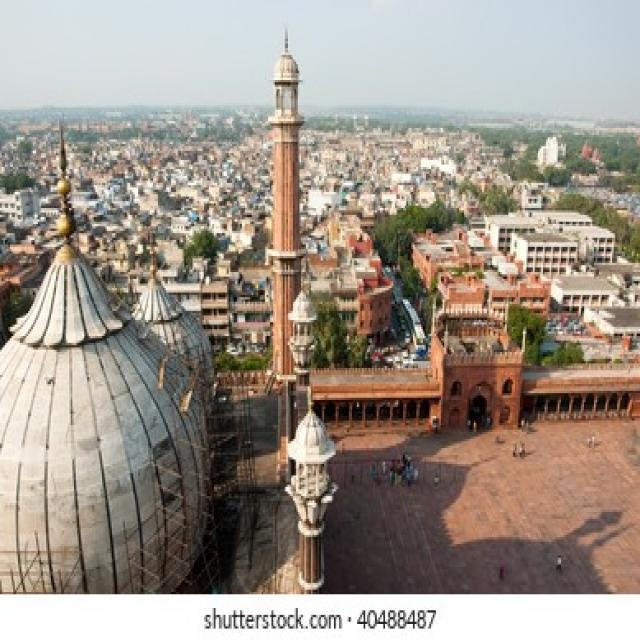

In [ ]:
# display inference on ALL test images
# this looks much better with longer training above

import glob
from IPython.display import Image, display

for imageName in glob.glob('/content/drive/MyDrive/Project/yolov5/runs/detect/exp/*.jpg'): #assuming JPG
    display(Image(filename=imageName))
    print("\n")

### Download the Weights of our Yolov5 custom model.

In [ ]:
# export your model's weights for future use
from google.colab import files
files.download('./runs/train/exp/weights/best.pt') 

In [ ]:
%cd /content/drive/MyDrive/Project/yolov5

/content/drive/MyDrive/Project/yolov5


### Validation, Detection and Prediction on trained PyTorch weight.

In [ ]:
# Validation on trained PyTorch weight
!python val.py --weights /content/drive/MyDrive/Project/yolov5/runs/train/yolov5s_results/weights/best.pt --data /content/drive/MyDrive/Project/yolov5/Ateet-1/data.yaml

val: data=/content/drive/MyDrive/Project/yolov5/Ateet-1/data.yaml, weights=['/content/drive/MyDrive/Project/yolov5/runs/train/yolov5s_results/weights/best.pt'], batch_size=32, imgsz=640, conf_thres=0.001, iou_thres=0.6, max_det=300, task=val, device=, workers=8, single_cls=False, augment=False, verbose=False, save_txt=False, save_hybrid=False, save_conf=False, save_json=False, project=runs/val, name=exp, exist_ok=False, half=False, dnn=False
requirements: YOLOv5 requirements "gitpython" "ipython" not found, attempting AutoUpdate...
Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/

requirements: 2 packages updated per /content/drive/MyDrive/Project/yolov5/requirements.txt
requirements: ⚠️ Restart runtime or rerun command for updates to take effect

YOLOv5 🚀 v7.0-32-g357cde9 Python-3.8.16 torch-1.13.0+cu116 CUDA:0 (Tesla T4, 15110MiB)

Fusing layers... 
Model summary: 322 layers, 86180143 parameters, 0 gradients
100% 755k/755k [00:00<00:0

In [ ]:
# Prediction on trained PyTorch weight
import torch

model = torch.hub.load('/content/drive/MyDrive/Project/yolov5', 'custom', path='/content/drive/MyDrive/Project/yolov5/runs/train/yolov5s_results/weights/best.pt', source='local')
model

YOLOv5 🚀 v7.0-32-g357cde9 Python-3.8.16 torch-1.13.0+cu116 CPU

Fusing layers... 
Model summary: 322 layers, 86180143 parameters, 0 gradients, 203.8 GFLOPs
Adding AutoShape... 


AutoShape(
  (model): DetectMultiBackend(
    (model): DetectionModel(
      (model): Sequential(
        (0): Conv(
          (conv): Conv2d(3, 80, kernel_size=(6, 6), stride=(2, 2), padding=(2, 2))
          (act): SiLU(inplace=True)
        )
        (1): Conv(
          (conv): Conv2d(80, 160, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
          (act): SiLU(inplace=True)
        )
        (2): C3(
          (cv1): Conv(
            (conv): Conv2d(160, 80, kernel_size=(1, 1), stride=(1, 1))
            (act): SiLU(inplace=True)
          )
          (cv2): Conv(
            (conv): Conv2d(160, 80, kernel_size=(1, 1), stride=(1, 1))
            (act): SiLU(inplace=True)
          )
          (cv3): Conv(
            (conv): Conv2d(160, 160, kernel_size=(1, 1), stride=(1, 1))
            (act): SiLU(inplace=True)
          )
          (m): Sequential(
            (0): Bottleneck(
              (cv1): Conv(
                (conv): Conv2d(80, 80, kernel_size=(1, 1), stride=(1, 1

image 1/1: 683x1024 1 monument
Speed: 417.1ms pre-process, 2717.3ms inference, 14.6ms NMS per image at shape (1, 3, 448, 640)


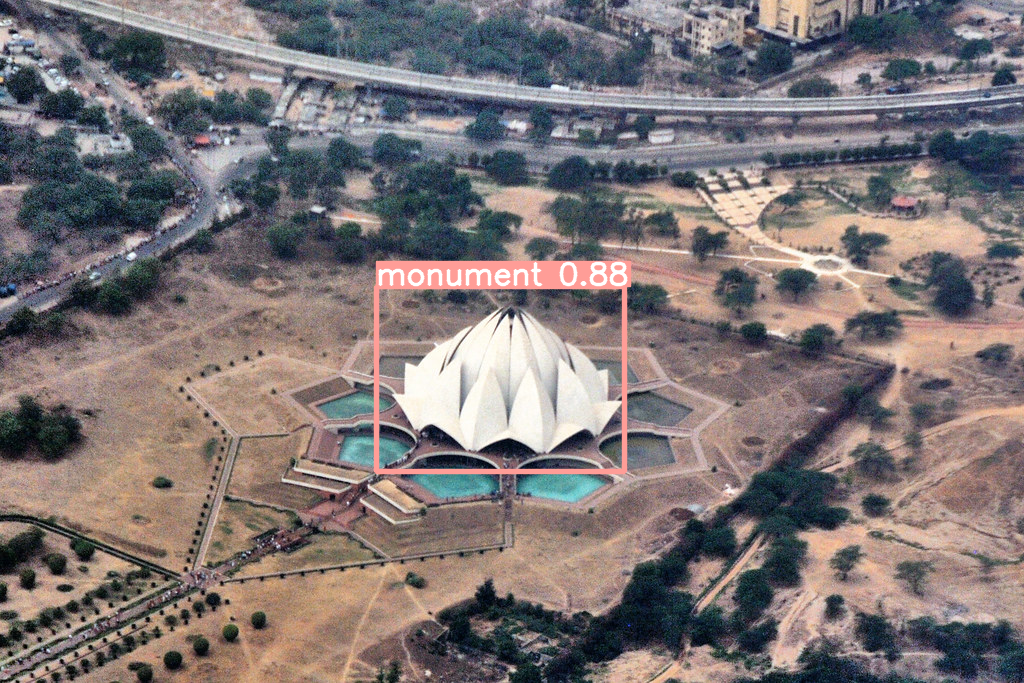

In [ ]:
# Image Prediction visualization
im = 'https://live.staticflickr.com/4147/5088537613_aa8ab861cb_b.jpg'

# Inference
results = model(im, size=640)

results.print()  
results.show()

In [ ]:
# Results of our prediction with coordinates and confidence
results.xyxy[0]
results.pandas().xyxy[0]

,xmin,ymin,xmax,ymax,confidence,class,name
0,376.129272,286.138428,624.383301,471.301819,0.883234,1,monument


### Install the Dependencies to export the model in TensorFlow.JS for Web Application.

In [ ]:
# Installation of coretools, onnx, tensorflow saved model and tensorflow.js 
!pip install -r requirements.txt coremltools onnx onnx-simplifier onnxruntime openvino-dev tensorflow-cpu

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     |████████████████████████████████| 1.5 MB 4.9 MB/s 
     |████████████████████████████████| 13.5 MB 44.3 MB/s 
     |████████████████████████████████| 2.0 MB 47.5 MB/s 
     |████████████████████████████████| 4.5 MB 49.9 MB/s 
     |████████████████████████████████| 5.8 MB 46.0 MB/s 
     |████████████████████████████████| 221.4 MB 53 kB/s 
     |████████████████████████████████| 182 kB 59.9 MB/s 
     |████████████████████████████████| 13.1 MB 60.4 MB/s 
     |████████████████████████████████| 237 kB 79.6 MB/s 
     |████████████████████████████████| 46 kB 3.4 MB/s 
     |████████████████████████████████| 33.8 MB 1.3 MB/s 
     |████████████████████████████████| 62 kB 1.3 MB/s 
     |████████████████████████████████| 36.4 MB 1.4 MB/s 
     |████████████████████████████████| 3.2 MB 54.5 MB/s 
     |████████████████████████████████| 1.7 MB 56.5 MB/s 
     |████████████████████████████

In [ ]:
# export the model from PyTorch model to TensorFLow JS
!python export.py --weights /content/drive/MyDrive/Project/yolov5/runs/train/yolov5s_results/weights/best.pt --include tfjs

export: data=data/coco128.yaml, weights=['/content/drive/MyDrive/Project/yolov5/runs/train/yolov5s_results/weights/best.pt'], imgsz=[640, 640], batch_size=1, device=cpu, half=False, inplace=False, keras=False, optimize=False, int8=False, dynamic=False, simplify=False, opset=12, verbose=False, workspace=4, nms=False, agnostic_nms=False, topk_per_class=100, topk_all=100, iou_thres=0.45, conf_thres=0.25, include=['tfjs']
YOLOv5 🚀 v7.0-32-g357cde9 Python-3.8.16 torch-1.13.0+cu116 CPU

Fusing layers... 
Model summary: 322 layers, 86180143 parameters, 0 gradients, 203.8 GFLOPs

PyTorch: starting from /content/drive/MyDrive/Project/yolov5/runs/train/yolov5s_results/weights/best.pt with output shape (1, 25200, 7) (165.0 MB)
2022-12-22 06:45:11.835999: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other 

In [ ]:
# validation of TensorFlow saved model on test dataset
!python val.py --weights /content/drive/MyDrive/Project/yolov5/runs/train/yolov5s_results/weights/best_saved_model --data /content/drive/MyDrive/Project/yolov5/Ateet-1/data.yaml

val: data=/content/drive/MyDrive/Project/yolov5/Ateet-1/data.yaml, weights=['/content/drive/MyDrive/Project/yolov5/runs/train/yolov5s_results/weights/best_saved_model'], batch_size=32, imgsz=640, conf_thres=0.001, iou_thres=0.6, max_det=300, task=val, device=, workers=8, single_cls=False, augment=False, verbose=False, save_txt=False, save_hybrid=False, save_conf=False, save_json=False, project=runs/val, name=exp, exist_ok=False, half=False, dnn=False
YOLOv5 🚀 v7.0-32-g357cde9 Python-3.8.16 torch-1.13.0+cu116 CPU

Loading /content/drive/MyDrive/Project/yolov5/runs/train/yolov5s_results/weights/best_saved_model for TensorFlow SavedModel inference...
2022-12-22 05:58:43.218342: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
Fo

In [ ]:
# detection of TensorFlow saved model on test dataset
!python detect.py --weights /content/drive/MyDrive/Project/yolov5/runs/train/yolov5s_results/weights/best_saved_model --source /content/drive/MyDrive/Project/yolov5/Ateet-1/test/images --data /content/drive/MyDrive/Project/yolov5/Ateet-1/data.yaml

detect: weights=['/content/drive/MyDrive/Project/yolov5/runs/train/yolov5s_results/weights/best_saved_model'], source=/content/drive/MyDrive/Project/yolov5/Ateet-1/test/images, data=/content/drive/MyDrive/Project/yolov5/Ateet-1/data.yaml, imgsz=[640, 640], conf_thres=0.25, iou_thres=0.45, max_det=1000, device=, view_img=False, save_txt=False, save_conf=False, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, visualize=False, update=False, project=runs/detect, name=exp, exist_ok=False, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 v7.0-32-g357cde9 Python-3.8.16 torch-1.13.0+cu116 CPU

Loading /content/drive/MyDrive/Project/yolov5/runs/train/yolov5s_results/weights/best_saved_model for TensorFlow SavedModel inference...
2022-12-22 06:07:05.597563: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CP

# Notebook End